# Генерация поэзии с Vanilla RNN

##### Автор: [Радослав Нейчев](https://www.linkedin.com/in/radoslav-neychev/), telegram: [@rads_ai](https://t.me/rads_ai)

Ваша основная задача: научиться генерироват стихи с помощью простой рекуррентной нейронной сети (Vanilla RNN). В качестве корпуса текстов для обучения будет выступать роман в стихах "Евгений Онегин" Александра Сергеевича Пушкина.

Подписывайтесь на канал @girafe-ai: [YouTube](https://youtube.com/@girafe-ai), [Telegram](https://t.me/girafe_ai)

In [1]:
# do not change the code in the block below
# __________start of block__________
import string
import os
from random import sample

import numpy as np
import torch, torch.nn as nn
import torch.nn.functional as F

from IPython.display import clear_output

import matplotlib.pyplot as plt
# __________end of block__________

In [2]:
# do not change the code in the block below
# __________start of block__________
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print('{} device is available'.format(device))
# __________end of block__________

cuda device is available


#### 1. Загрузка данных.

In [3]:
# do not change the code in the block below
# __________start of block__________
!wget https://raw.githubusercontent.com/neychev/small_DL_repo/master/datasets/onegin.txt

with open('onegin.txt', 'r') as iofile:
    text = iofile.readlines()

text = "".join([x.replace('\t\t', '').lower() for x in text])
# __________end of block__________

--2026-10-14 19:54:04--  https://raw.githubusercontent.com/neychev/small_DL_repo/master/datasets/onegin.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 262521 (256K) [text/plain]
Saving to: ‘onegin.txt’

onegin.txt          100%[===================>] 256.37K  --.-KB/s    in 0.02s   

2026-10-14 19:54:05 (13.2 MB/s) - ‘onegin.txt’ saved [262521/262521]



#### 2. Построение словаря и предобработка текста
В данном задании требуется построить языковую модель на уровне символов. Приведем весь текст к нижнему регистру и построим словарь из всех символов в доступном корпусе текстов. Также добавим токен `<sos>`.

In [4]:
# do not change the code in the block below
# __________start of block__________
tokens = sorted(set(text.lower())) + ['<sos>']
num_tokens = len(tokens)

assert num_tokens == 84, "Check the tokenization process"

token_to_idx = {x: idx for idx, x in enumerate(tokens)}
idx_to_token = {idx: x for idx, x in enumerate(tokens)}

assert len(tokens) == len(token_to_idx), "Mapping should be unique"

print("Seems fine!")


text_encoded = [token_to_idx[x] for x in text]
# __________end of block__________

Seems fine!


__Ваша задача__: обучить классическую рекуррентную нейронную сеть (Vanilla RNN) предсказывать следующий символ на полученном корпусе текстов и сгенерировать последовательность длины 100 для фиксированной начальной фразы.

Вы можете воспользоваться кодом с занятие №6 или же обратиться к следующим ссылкам:
* Замечательная статья за авторством Andrej Karpathy об использовании RNN: [link](http://karpathy.github.io/2015/05/21/rnn-effectiveness/)
* Пример char-rnn от Andrej Karpathy: [github repo](https://github.com/karpathy/char-rnn)
* Замечательный пример генерации поэзии Шекспира: [github repo](https://github.com/spro/practical-pytorch/blob/master/char-rnn-generation/char-rnn-generation.ipynb)

Данное задание является достаточно творческим. Не страшно, если поначалу оно вызывает затруднения. Последняя ссылка в списке выше может быть особенно полезна в данном случае.

Далее для вашего удобства реализована функция, которая генерирует случайный батч размера `batch_size` из строк длиной `seq_length`. Вы можете использовать его при обучении модели.

In [5]:
# do not change the code in the block below
# __________start of block__________
batch_size = 256
seq_length = 100
start_column = np.zeros((batch_size, 1), dtype=int) + token_to_idx['<sos>']

def generate_chunk():
    global text_encoded, start_column, batch_size, seq_length

    start_index = np.random.randint(0, len(text_encoded) - batch_size*seq_length - 1)
    data = np.array(text_encoded[start_index:start_index + batch_size*seq_length]).reshape((batch_size, -1))
    yield np.hstack((start_column, data))
# __________end of block__________

Пример батча:

In [6]:
next(generate_chunk())

array([[83, 58, 50, ..., 45, 55, 45],
       [83, 76,  1, ..., 59,  1, 52],
       [83, 45, 46, ...,  1, 51, 50],
       ...,
       [83,  1, 63, ..., 53, 57,  1],
       [83, 47,  1, ..., 48, 53, 66],
       [83,  1, 46, ...,  0, 53, 58]])

Далее вам предстоит написать код для обучения модели и генерации текста.

In [7]:
# your beautiful experiments here
class RNN(nn.Module):
  def __init__(self, input_dim, hidden_dim, output_dim, num_layers=1):
    super().__init__()

    self.hidden_dim = hidden_dim
    self.num_layers = num_layers

    self.embedding = nn.Embedding(input_dim, hidden_dim)
    self.rnn = nn.RNN(hidden_dim, hidden_dim, num_layers, batch_first=True)
    self.fc = nn.Linear(hidden_dim, output_dim)

  def forward(self, x, hidden=None):
    # x : (batch_size, seq_len)
    emb = self.embedding(x) # (batch_size, seq_len, hidden_dim)
    out, h = self.rnn(emb, hidden) # out: (batch_size, seq_len, hidden_dim)
    out = self.fc(out) # logits: (batch_size, seq_len, output_dim)
    return out, h

  def init_hidden(self):
    return torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=device)

In [13]:
def generate_sample(char_rnn, seed_phrase=None, max_length=200, temperature=1.0, device=device):
    '''
    The function generates text given a phrase of length at least SEQ_LENGTH.
    :param seed_phrase: prefix characters. The RNN is asked to continue the phrase
    :param max_length: maximum output length, including seed_phrase
    :param temperature: coefficient for sampling.  higher temperature produces more chaotic outputs,
                        smaller temperature converges to the single most likely output
    '''

    if seed_phrase is not None:
        x_sequence = [token_to_idx['<sos>']] + [token_to_idx[token] for token in seed_phrase]
    else:
        x_sequence = [token_to_idx['<sos>']]

    x_sequence = torch.tensor([x_sequence], dtype=torch.int64).to(device)

    #feed the seed phrase, if any

    hidden = None
    with torch.no_grad():
      out, hidden = char_rnn(x_sequence, hidden)
      last_token_logits = out[:, -1, :]

      for _ in range(max_length - x_sequence.shape[1]):
        scaled_logits = last_token_logits / max(temperature, 1e-5)
        probs = F.softmax(scaled_logits, dim=-1)

        # случайный выбор символа относительно вероятностей
        next_token = torch.multinomial(probs, num_samples=1)

        # добавляем токен к последовательности
        x_sequence = torch.cat([x_sequence, next_token], dim=-1)

        # вычисляем логиты следующего класса
        out, hidden = char_rnn(next_token, hidden)
        last_token_logits = out[:, -1, :]

    return ''.join([tokens[ix] for ix in x_sequence.cpu().data.numpy()[0]])

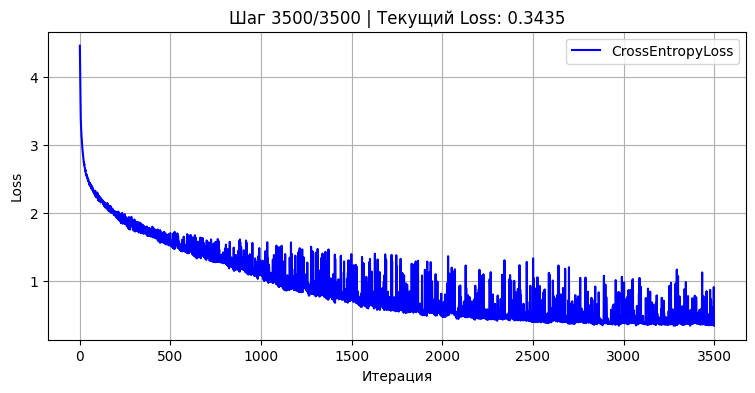

--- Результат на шаге 3500 ---
<sos> мой дядя самых честных правилица
в аклирая,
и ничего с наконец ответ.
тесчастью живой,
иль при вими священные дней
(намним пенараспевал.
живо проходит с умом.



xi

он мог бы чувства обнаружить,
а не щетиниться, как зверь;
он должен был обезоружить
младое сердце. «но теперь
уж поздно; время простойный
увял был трудно была.



xix

весь вечер ленский был рассеян,
то молчалив, то весел вновь;
но тот, кто музою взлелеян,
всегда таков: нахмуря бровь,
садился он за клавикорды
и брал на них одни ак
----------------------------------------


In [17]:
model = RNN(input_dim=num_tokens, hidden_dim=256, output_dim=num_tokens, num_layers=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

num_iterations = 3500
loss_history = []

for step in range(1, num_iterations+1):
  model.train()

  chunk = next(generate_chunk())
  chunk = torch.tensor(chunk, dtype=torch.int64, device=device)

  inputs = chunk[:, :-1]
  targets = chunk[:, 1:]

  # forward pass
  optimizer.zero_grad()
  logits, _ = model(inputs)

  # подсчёт ошибки - CrossEntropyLoss принимает (n, c) и (n,)
  loss = criterion(logits.reshape(-1, num_tokens), targets.reshape(-1))

  loss.backward()
  torch,nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
  optimizer.step()

  loss_history.append(loss.item())

  if step % 100 == 0:
    clear_output(True)

    plt.figure(figsize = (9, 4))
    plt.plot(loss_history, label="CrossEntropyLoss", color = "blue")
    plt.xlabel('Итерация')
    plt.ylabel('Loss')
    plt.title(f'Шаг {step}/{num_iterations} | Текущий Loss: {loss.item():.4f}')
    plt.grid(True)
    plt.legend()
    plt.show()

    test_seed = "мой дядя честных правил"
    generated_sample = generate_sample(model, " мой дядя самых честных правил", max_length=500, temperature=0.25)
    print(f"--- Результат на шаге {step} ---\n{generated_sample}\n{'-'*40}")

В качестве иллюстрации ниже доступен график значений функции потерь, построенный в ходе обучения авторской сети (сам код для ее обучения вам и предстоит написать).

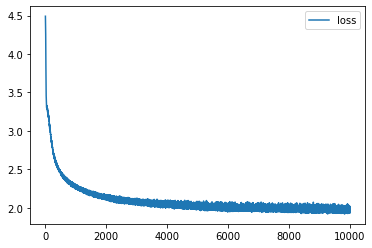

Шаблон функции `generate_sample` также доступен ниже. Вы можете как дозаполнить его, так и написать свою собственную функцию с нуля. Не забывайте, что все примеры в обучающей выборке начинались с токена `<sos>`.

Пример текста сгенерированного обученной моделью доступен ниже. Не страшно, что в тексте много несуществующих слов. Используемая модель очень проста: это простая классическая RNN.

In [40]:
print(generate_sample(model, ' мой дядя самых честных правил', max_length=500, temperature=0.3))

<sos> мой дядя самых честных правилица
в аклирая,
старай и гнув оба.



xxxv

но я взор себя влежного пьян,
пора, деревня том
и неочирняных, в коляю печальный
ему готовить честный гроб
и тихо целить в бледный лоб
на благородном расстоянье;
но отослать его к отцам
едва ль приятно будет вам.



xxxiv

что ж, если вашим пистолетом
сражен приятель молодой,
нескромным взглядом, иль ответом,
или безделицей иной
вас оскорбивший за бутылкой,
иль даже сам в думал я влюблена».
и между тем луна сияла
и томным 


### Сдача задания
Сгенерируйте десять последовательностей длиной 500, используя строку ' мой дядя самых честных правил'. Температуру для генерации выберите самостоятельно на основании визуального качества генериуремого текста. Не забудьте удалить все технические токены в случае их наличия.

Сгенерированную последовательность сохрание в переменную `generated_phrase` и сдайте сгенерированный ниже файл в контест.

In [44]:
generated_phrases = [
    generate_sample(
        model,
        ' мой дядя самых честных правил',
        max_length=501,
        temperature=0.3
    ).replace('<sos>', '')
    for _ in range(10)
]
print([len(i) for i in generated_phrases])

[500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


In [45]:
# do not change the code in the block below
# __________start of block__________

import json
if 'generated_phrases' not in locals():
    raise ValueError("Please, save generated phrases to `generated_phrases` variable")

for phrase in generated_phrases:

    if not isinstance(phrase, str):
        raise ValueError("The generated phrase should be a string")

    if len(phrase) != 500:
        raise ValueError("The `generated_phrase` length should be equal to 500")

    assert all([x in set(tokens) for x in set(list(phrase))]), 'Unknown tokens detected, check your submission!'


submission_dict = {
    'token_to_idx': token_to_idx,
    'generated_phrases': generated_phrases
}

with open('submission_dict.json', 'w') as iofile:
    json.dump(submission_dict, iofile)
print('File saved to `submission_dict.json`')
# __________end of block__________

File saved to `submission_dict.json`


На этом задание завершено. Поздравляем!